
---
date: "2026-10-23"
date-modified: last-modified
format:
  html:
    toc: true
---


# Why Measure Theory

**Prerequisites:** [Set Theory Preliminaries](pre-set-theory.ipynb) · [The Cantor Set](cantor-set.ipynb) · [Probability](probability.ipynb)

Measure theory grew out of several subjects that, before it, looked unrelated: the geometry of length, area and volume; the theory of the integral; probability; and the description of quantities spread over a space. It unified them, and it also pushed each of them much further. This note explains what each of these subjects asks of a theory of "size", why the obvious wish (a size for *every* set) cannot be granted, and why the additivity we need must be *countable*. These two facts shape everything that follows: measures are defined on [σ-algebras](sigma-algebra.ipynb), and they are required to be countably additive.

## 1\. Four Sources of Measure Theory

### 1.1\. Length, Area, and Volume

A measure is an abstraction of length, area and volume, and their analogues in higher dimensions. Measure theory carries these notions to arbitrary sets, to any dimension, and to abstract spaces with no geometry at all.

For simple shapes we know the answers: rectangles, triangles, discs. The questions start when sets become complicated.

- The [Cantor set](cantor-set.ipynb#measure-zero), built by repeatedly removing middle thirds, has length $0$. This was not obvious and needed an argument.
- What is the area of the set of points of the plane whose two coordinates are both rational? What about the points with irrational coordinates?
- Take a square, divide it into a $3 \times 3$ grid, remove the middle square, and repeat the process in each of the eight remaining squares forever. What is the area of what is left?

Measure theory answers such questions and, more importantly, tells us exactly which sets can be given a size at all: the **measurable sets**.

### 1.2\. The Integral

The Riemann integral computes the area under a graph by cutting the *domain* into small intervals, building rectangles on them, and adding their areas. It has a serious defect: the Riemann integrable functions are not closed under limits. A sequence of Riemann integrable functions $f_n$ can converge to a function $f$ that is not Riemann integrable.

::: {#exm-riemann-not-closed}
## A Limit of Riemann Integrable Functions That Is Not Riemann Integrable

Enumerate the rationals of $[0, 1]$ as $q_1, q_2, q_3, \dots$ and let $f_n$ be $1$ at $q_1, \dots, q_n$ and $0$ elsewhere on $[0,1]$. Each $f_n$ has finitely many discontinuities, so it is Riemann integrable, with integral $0$. For every $x$, $f_n(x)$ increases to $f(x)$, where $f = 1$ on the rationals and $0$ on the irrationals of $[0,1]$. But every subinterval of $[0,1]$ contains both rationals and irrationals, so every upper Riemann sum of $f$ is $1$ and every lower sum is $0$: $f$ is not Riemann integrable.
:::

The **Lebesgue integral**, built on measure, is not a different integral: on functions that have a Riemann integral it gives the same value. What it does is enlarge the class of integrable functions, and make it stable under limits.

### 1.3\. Probability

Since Kolmogorov's work in the 1930s, advanced [probability](probability.ipynb) is built on measure theory. His observation was that what we expect of a probability is what we expect of an area: if two events are disjoint, the probability of their union is the sum of their probabilities, just as the area of two disjoint shapes is the sum of their areas. A probability is a measure that assigns a number to the subsets (events) of a sample space, and the whole theory can be translated:

| Probability | Measure theory |
|---|---|
| probability $P$ | a measure with total mass $1$ |
| event | measurable set |
| random variable | measurable function |
| expectation $E[X]$ | integral $\int X \, dP$ |
| "almost surely" | "almost everywhere" |

Many books even write expectations with the integral sign, and every theorem proved about the Lebesgue integral becomes a theorem about expectations.

Measure theory is not just a dictionary here; it removes old difficulties. Elementary probability treats discrete random variables (Bernoulli, binomial) and continuous ones (normal, gamma) separately, and proves every result twice: for instance $E[X] = \sum_i x_i P(X = x_i)$ in one case and $E[X] = \int x\, f(x)\, dx$ with a density $f$ in the other, while mixed variables, neither discrete nor continuous, fit neither formula. In measure theory all three are the single integral $\int X\, dP$. In the same way, one-variable distributions (random variables) and several-variable distributions (random vectors) are both just measures, on $\mathbb{R}$ and on $\mathbb{R}^n$.

### 1.4\. Distributions of a Quantity

Physics describes the distribution of mass or electric charge in space by a **density function**: more in some places, less in others. Economics describes the distribution of wealth or income in a society. For the second example there is no natural geometry: the "space" is a population $\Omega$, and a density function has no meaning on an abstract set like $\Omega$.

A measure removes the need for a density. A distribution of a quantity over $\Omega$ is simply a measure $\mu$ on $\Omega$: for a group $A \subseteq \Omega$, $\mu(A)$ is the total amount of the quantity in $A$, for example the total wealth of the people in $A$. Averages of the quantity become integrals.


## 2\. What We Want From a Measure

A measure on a set $X$ should assign to subsets $E \subseteq X$ a size $\mu(E) \ge 0$. Some sets (a half-plane, say) have infinite size, so we allow the value $\infty$:
$$\mu : 2^X \to [0, \infty],$$
where $2^X$ denotes the family of all subsets of $X$. The most important property we expect is **additivity**:
$$E \cap F = \emptyset \implies \mu(E \cup F) = \mu(E) + \mu(F).$$

### 2.1\. Not Every Set Can Be Measured

It would be ideal to assign a size to *every* subset, in a way that agrees with ordinary volume on ordinary shapes, even for sets built by infinite limiting processes like the Cantor set. The answer is no.

::: {#thm-banach-tarski}
## The Banach–Tarski Paradox

A solid ball in $\mathbb{R}^3$ can be partitioned into finitely many pieces (five suffice) which, after being moved by rotations and translations only, can be reassembled into two solid balls, each congruent to the original ball.
:::

The proof (not given here) is algebraic, uses group theory and the axiom of choice, and the pieces are so wild that they cannot be drawn.

::: {#cor-no-volume-on-all-sets}
## No Volume on All Subsets of $\mathbb{R}^3$

There is no function $\mu : 2^{\mathbb{R}^3} \to [0, \infty]$ that is finitely additive, unchanged by rotations and translations, and gives a ball of radius $r$ its usual volume $\tfrac43 \pi r^3$.
:::

::: {.callout-tip collapse="true"}
## Proof of @cor-no-volume-on-all-sets
Suppose such a $\mu$ existed. Let $B$ be a ball, decomposed as in @thm-banach-tarski into pieces $P_1, \dots, P_k$, and let $B_1, B_2$ be the two balls obtained by moving the pieces. By finite additivity and invariance under rigid motions,
$$\mu(B) = \sum_{i=1}^k \mu(P_i) = \mu(B_1) + \mu(B_2) = 2\mu(B).$$
Since $0 < \mu(B) = \tfrac43\pi r^3 < \infty$, this is impossible. $\blacksquare$
:::

So measure theory gives up the idea of a measure on all subsets. A measure will be defined only on a *family* of subsets of $X$, and the question becomes which properties this family must have.

### 2.2\. Why Additivity Must Be Countable

Later constructions need limits, and finite additivity is not enough for them. Suppose we know the area of rectangles (length times width) and want the area of a disc. Using only additivity, we must cut the disc into rectangles. Lay a grid over the disc and keep the squares that lie inside it; the squares that stick out are subdivided by a finer grid, the new squares inside are kept, and so on. The process never ends: the open disc is cut into **countably infinitely many** squares (the figure below shows the first generations). To get its area from the areas of the squares we need
$$\mu\Big(\bigcup_{i=1}^\infty E_i\Big) = \sum_{i=1}^\infty \mu(E_i) \qquad \text{for pairwise disjoint } E_1, E_2, \dots$$
This is **countable additivity**. It does not follow from finite additivity; one would need some continuity of $\mu$ in addition.

::: {#exm-finitely-not-countably-additive}
## Finitely Additive but Not Countably Additive

On $X = \mathbb{N}$ let $\nu(E) = 0$ if $E$ is finite and $\nu(E) = \infty$ if $E$ is infinite. If $E \cap F = \emptyset$, then $E \cup F$ is finite exactly when both are, so $\nu(E \cup F) = \nu(E) + \nu(F)$ in all cases: $\nu$ is finitely additive. But $\mathbb{N} = \bigcup_n \{n\}$ is a disjoint union with
$$\nu(\mathbb{N}) = \infty \ne 0 = \sum_n \nu(\{n\}).$$
:::

Countable additivity has a consequence for the family of measurable sets: if $E_1, E_2, \dots$ are measurable, their union must be measurable too, so that $\mu$ is defined on it. Together with closure under complements, this is the notion of a [σ-algebra](sigma-algebra.ipynb), studied next.

The figure shows the disc filled by dyadic squares: generation $k$ consists of the squares of side $2^{-k}$ that lie inside the disc and are not already covered. The total area of the squares kept up to generation $k$ increases to the area $\pi$ of the disc, as countable additivity predicts.

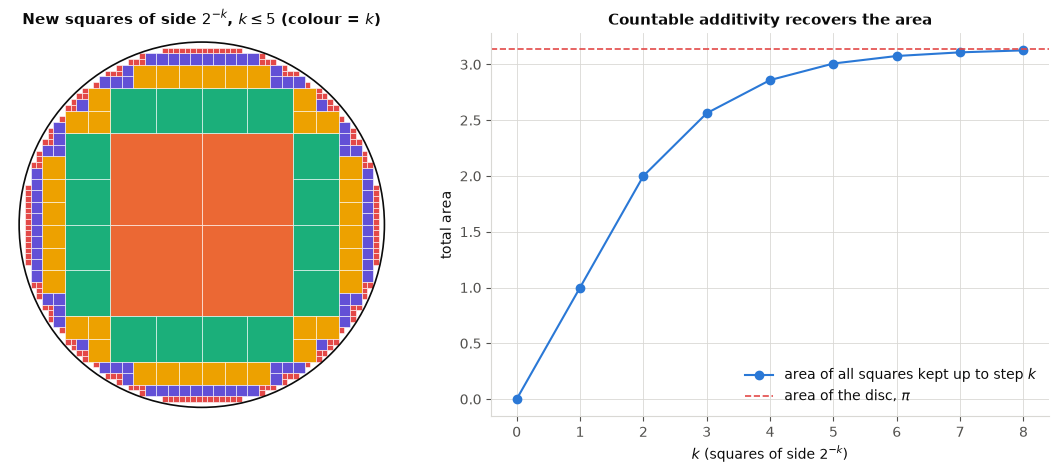

area kept with squares of side 2^-8: 3.1255  pi = 3.1416


In [1]:

import numpy as np
import matplotlib.pyplot as plt

BLUE, ORANGE, AQUA, YELLOW, VIOLET, RED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6", "#e34948"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#d9d8d4"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "legend.frameon": False, "font.size": 10})

from matplotlib.patches import Rectangle, Circle

def kept_squares(k):
    """Closed dyadic squares of side 2^-k lying inside the open unit disc."""
    h = 2.0 ** -k
    idx = np.arange(-2**k, 2**k)
    out = []
    for i in idx:
        for j in idx:
            x0, y0 = i * h, j * h
            far = max(abs(x0), abs(x0 + h)) ** 2 + max(abs(y0), abs(y0 + h)) ** 2
            if far < 1:
                out.append((x0, y0, h))
    return out

colors = [BLUE, ORANGE, AQUA, YELLOW, VIOLET, RED]
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11, 4.8), gridspec_kw={"width_ratios": [1, 1.25]})
covered = set()
areas = []
for k in range(0, 9):
    sq = kept_squares(k)
    areas.append(len(sq) * (2.0 ** -k) ** 2)
    if k <= 5:
        for (x0, y0, h) in sq:
            parent = (np.floor(x0 * 2 ** (k - 1)) / 2 ** (k - 1), np.floor(y0 * 2 ** (k - 1)) / 2 ** (k - 1)) if k else None
            if k and parent in covered:
                continue
            ax.add_patch(Rectangle((x0, y0), h, h, facecolor=colors[k], edgecolor="white", lw=0.4))
        covered = {(x0, y0) for (x0, y0, h) in sq}
ax.add_patch(Circle((0, 0), 1, fill=False, edgecolor=INK, lw=1.2))
ax.set_xlim(-1.05, 1.05); ax.set_ylim(-1.05, 1.05); ax.set_aspect("equal"); ax.grid(False)
ax.set_title(r"New squares of side $2^{-k}$, $k \leq 5$ (colour = $k$)")
ax.axis("off")

ax2.plot(range(len(areas)), areas, "o-", color=BLUE, label="area of all squares kept up to step $k$")
ax2.axhline(np.pi, color=RED, ls="--", lw=1.2, label=r"area of the disc, $\pi$")
ax2.set_xlabel(r"$k$ (squares of side $2^{-k}$)"); ax2.set_ylabel("total area")
ax2.set_title("Countable additivity recovers the area")
ax2.legend(loc="lower right")
plt.tight_layout(); plt.show()
print("area kept with squares of side 2^-8:", round(areas[-1], 4), " pi =", round(np.pi, 4))